# Task #2: Baseline Classification (final version)
**Question:** Which kidney waitlist candidates have an adverse removal within 1 year of listing?

**Target (exact definition):** `y = 1` if this registration ended with an adverse removal (REM_CD 5, 8, 13, 21, 23: died, medically unsuitable, or too sick) **observed during this registration within 365 days of INIT_DATE**. Everything else is `y = 0`. A 0 does not mean the patient did well. For non-medical removals, it means no adverse removal was observed during this registration; we don't know what happened to them afterward.

Order: logistic regression (baseline) → Random Forest → XGBoost, all on the same split and the same features.

**Decisions and where they come from:**
- **Race/ethnicity (ETHCAT)** is not a model feature (Deepti). It stays in the data for the fairness check.
- **REM_CD groups** are checked against the STAR Kidney Student Data Guide (REM_CD Codes tab). Codes 6 (refused transplant) and 12 (condition improved) are their own groups and stay in the model as `y = 0` (Deepti).
- **Non-medical removals** stay `y = 0` by default. Section 10 runs the sensitivity check Deepti asked for: drop them, refit, compare PR-AUC.
- **REGION** is not used: the guide marks it as region *where transplanted*, which leaks the outcome.
- **ON_DIALYSIS** is replaced by dialysis status and dialysis vintage built from DIALYSIS_DATE vs INIT_DATE, because the guide warns ON_DIALYSIS may include dialysis that started after listing.
- **Brier** is reported as a Brier Skill Score against predicting the prevalence for everyone, and **PR-AUC** is compared to the prevalence (Deepti).

**Before running:** paste the data link into `url` in section 1, then Runtime → Run all.

**DUA reminder:** only aggregate tables and figures are printed. Never commit row-level data or saved prediction files to GitHub.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score, roc_auc_score, brier_score_loss
from xgboost import XGBClassifier

RANDOM_STATE = 42

## 1. Load data

In [2]:

url = "https://raw.githubusercontent.com/Break-Through-Tech/Healthcare-1A-predicting-organ-transplant-waitlist-outcomes-and-optimizing-allocation/main/data/kidney_waitlist_analytic.csv.gz"
df = pd.read_csv(url)
print(df.shape)
print(df.columns.tolist())

/tmp/ipykernel_2545/987314552.py:2: DtypeWarning: Columns (22,23,24,26,27,30) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(url)


(494862, 38)
['ON_DIALYSIS', 'A2A2B_ELIGIBILITY', 'GENDER', 'ABO', 'BMI_TCR', 'FUNC_STAT_TCR', 'INIT_STAT', 'INIT_CPRA', 'END_CPRA', 'REM_CD', 'DAYSWAIT_CHRON', 'END_STAT', 'INIT_AGE', 'DIALYSIS_DATE', 'END_DATE', 'INIT_DATE', 'ETHCAT', 'PT_CODE', 'DAYSWAIT_ALLOC', 'COMPOSITE_DEATH_DATE', 'REGION', 'WL_ID_CODE', 'PREV_TX', 'TX_DATE', 'DON_TY', 'DIAG_KI', 'MULTIORG', 'ORGAN', 'PSTATUS', 'PTIME', 'TRR_ID_CODE', 'DONOR_ID', 'LISTING_CTR_CODE', 'outcome', 'event_adverse', 'event_transplant', 'censored', 'days_to_event']


## 2. CONFIG
REM_CD groups match the **REM_CD Codes** tab of the STAR Kidney Student Data Guide. Features are listing-time only, following the guide's **Variables** tab.

In [3]:
LIST_DATE_COL  = "INIT_DATE"
END_DATE_COL   = "END_DATE"    # never blank; for still-waiting rows it is the data cut-off
REMCD_COL      = "REM_CD"      # blank = still waiting at the cut-off
PATIENT_ID_COL = "PT_CODE"

HORIZON_DAYS = 365

REMCD_GROUPS = {
    "Adverse (died / too sick)":        {5, 8, 13, 21, 23},
    "Transplanted (this registration)": {2, 4, 15, 18, 19, 41, 42, 43, 44, 45},
    "Transplanted elsewhere":           {3, 14, 22},
    "Administrative":                   {7, 9, 10, 11, 16, 17, 20, 24, 40},
    "Refused transplant":               {6},
    "Condition improved":               {12},
}
ADVERSE_CODES = REMCD_GROUPS["Adverse (died / too sick)"]

# Sensitivity check (section 10): these groups are dropped and the models refit.
# Code 12 is a medical reason (good outcome), so it is not in this list.
NON_MEDICAL_GROUPS = ["Administrative", "Transplanted elsewhere", "Refused transplant"]
RUN_SENSITIVITY = True

DATA_CUTOFF = None   # None = END_DATE of still-waiting rows

# Listing-time features. Not used: REGION (leaky), ON_DIALYSIS (replaced, see section 4), ETHCAT (fairness only).
NUMERIC_FEATURES     = ["INIT_AGE", "BMI_TCR", "INIT_CPRA"]
CATEGORICAL_FEATURES = ["GENDER", "ABO", "FUNC_STAT_TCR", "INIT_STAT"]
DERIVED_FEATURES     = ["dialysis_vintage_days", "on_dialysis_at_listing"]   # built in section 4
FAIRNESS_ONLY        = ["ETHCAT"]   # kept in the data, never a feature

SPLIT = "temporal"          # "temporal" or "random"
TEST_START = "2021-03-15"   # kidney Acuity Circles start; test set = listings from this date on

## 2b. REM_CD check and non-medical removals
Uses REM_CD directly on the full extract (all registrations). Each group is counted three ways: rows (registrations), unique patients with at least one, and patients whose only outcome was that type.

In [4]:
REMCD_MEANING = {
    2: "Deceased donor tx, removed by tx center", 3: "Txed at another center",
    4: "Deceased donor tx, removed by tx center", 5: "Medically unsuitable", 6: "Refused transplant",
    7: "Transferred to another center", 8: "Died", 9: "Other", 10: "Candidate listed in error",
    11: "Cand. listed for unaccept. antigens only", 12: "Cand. condition improved, tx not needed",
    13: "Cand. cond. deteriorated, too sick to tx", 14: "Tx at another center (multiple-listing)",
    15: "Living donor tx, removed by tx center", 16: "Candidate removed in error",
    17: "Changed to KP (by system)", 18: "Deceased donor emergency tx", 19: "Deceased donor multi-organ tx",
    20: "Program inactive for 2+ years", 21: "Patient died during tx procedure",
    22: "Transplanted in another country", 23: "Patient died during living donor tx procedure",
    24: "Unable to contact candidate", 40: "Waiting for KP, will not accept isol. organ",
    41: "Also waiting for isol organ; recvd kidney", 42: "Also waiting for isol organ; recvd pancreas",
    43: "Also waiting for KP; recvd KP", 44: "Also waiting for KP; recvd kidney alone",
    45: "Also waiting for KP; recvd pancreas alone",
}
CODE_TO_GROUP = {c: g for g, codes in REMCD_GROUPS.items() for c in codes}

rem = pd.to_numeric(df[REMCD_COL], errors="coerce")
codes_table = (rem.value_counts(dropna=False).rename("rows").to_frame()
               .assign(meaning=lambda t: [REMCD_MEANING.get(c, "STILL WAITING" if pd.isna(c) else "NOT IN GUIDE") for c in t.index],
                       group=lambda t: [CODE_TO_GROUP.get(c, "Still waiting" if pd.isna(c) else "UNMAPPED") for c in t.index])
               .sort_index())
print(codes_table.to_string(), "\n")
unmapped = rem.notna() & ~rem.isin(CODE_TO_GROUP.keys())
print(f"Rows with a REM_CD not in the guide: {unmapped.sum():,}  (should be 0)\n")

def removal_counts(codes, label):
    is_type = rem.isin(codes)   # blank REM_CD (still waiting) counts as False
    return {"group": label,
            "rows (registrations)": int(is_type.sum()),
            "patients with at least one": df.loc[is_type, PATIENT_ID_COL].nunique(),
            # every registration for that patient ended this way
            "patients with only this outcome": int(is_type.groupby(df[PATIENT_ID_COL]).all().sum())}

removals = pd.DataFrame([removal_counts(REMCD_GROUPS[g], g) for g in
                         ["Administrative", "Transplanted elsewhere", "Refused transplant", "Condition improved"]]).set_index("group")
print(f"Total unique patients in extract: {df[PATIENT_ID_COL].nunique():,}")
removals

          rows                                      meaning                             group
REM_CD                                                                                       
4.0     167181      Deceased donor tx, removed by tx center  Transplanted (this registration)
6.0       2464                           Refused transplant                Refused transplant
7.0       6873                Transferred to another center                    Administrative
8.0      34518                                         Died         Adverse (died / too sick)
9.0      30114                                        Other                    Administrative
12.0      2351      Cand. condition improved, tx not needed                Condition improved
13.0     35219     Cand. cond. deteriorated, too sick to tx         Adverse (died / too sick)
14.0     36584      Tx at another center (multiple-listing)            Transplanted elsewhere
15.0     63742        Living donor tx, removed by tx center 

,rows (registrations),patients with at least one,patients with only this outcome
group,,,
Administrative,45332,42474,24105
Transplanted elsewhere,37243,30712,3068
Refused transplant,2464,2442,1852
Condition improved,2351,2312,1919


## 3. Build the label
- **Eligible rows:** registrations listed at least `HORIZON_DAYS` before the cut-off, so everyone has a full year of follow-up (the guide's suggested fixed-window label).
- **y = 1:** adverse REM_CD with END_DATE within `HORIZON_DAYS` of INIT_DATE.
- **y = 0:** everything else, including codes 6 and 12, non-medical removals, transplants, and anyone still registered at 1 year.
- **Dropped:** only rows with a negative or missing duration (data-entry errors).

In [5]:
d = df.copy()
d[LIST_DATE_COL] = pd.to_datetime(d[LIST_DATE_COL], errors="coerce")
d[END_DATE_COL]  = pd.to_datetime(d[END_DATE_COL],  errors="coerce")
d["rem"] = pd.to_numeric(d[REMCD_COL], errors="coerce")
d["remcd_group"] = d["rem"].map(CODE_TO_GROUP)
d.loc[d["rem"].isna(), "remcd_group"] = "Still waiting"
d["remcd_group"] = d["remcd_group"].fillna("UNMAPPED")

cutoff = pd.Timestamp(DATA_CUTOFF) if DATA_CUTOFF else d.loc[d["rem"].isna(), END_DATE_COL].max()
print("Data cut-off:", cutoff.date())

log = {"start": len(d)}
d = d[d[LIST_DATE_COL].notna()]
d = d[d[LIST_DATE_COL] <= cutoff - pd.Timedelta(days=HORIZON_DAYS)]
log[f"listed >= {HORIZON_DAYS} days before cut-off"] = len(d)
days = (d[END_DATE_COL] - d[LIST_DATE_COL]).dt.days
d = d[days.notna() & (days >= 0)].copy()
days = days.loc[d.index]
log["after dropping missing/negative durations"] = len(d)

d["y"] = (d["rem"].isin(ADVERSE_CODES) & (days <= HORIZON_DAYS)).astype(int)

for k, v in log.items(): print(f"{k:45s} {v:>9,}")
print(f"\n1-year adverse rate (y = 1): {d['y'].mean():.3f}")
if "event_adverse" in d:
    print(f"Team's event_adverse on the same rows (any time, no 1-year window): {d['event_adverse'].mean():.3f}")
print()
print(pd.crosstab(d["remcd_group"], d["y"]))

Data cut-off: 2026-07-03
start                                           494,862
listed >= 365 days before cut-off               442,138
after dropping missing/negative durations       442,082

1-year adverse rate (y = 1): 0.038
Team's event_adverse on the same rows (any time, no 1-year window): 0.156

y                                      0      1
remcd_group                                    
Administrative                     44584      0
Adverse (died / too sick)          52098  16739
Condition improved                  2280      0
Refused transplant                  2441      0
Still waiting                      64076      0
Transplanted (this registration)  223767      0
Transplanted elsewhere             36097      0


## 4. Features
Dialysis comes from DIALYSIS_DATE vs INIT_DATE, as the guide recommends: blank or after listing = not on dialysis at listing, vintage 0. ABO subtypes are grouped (A1, A2 → A; A1B, A2B → AB). The table compares the new dialysis flag with ON_DIALYSIS, which shows how many "Y" values come from dialysis that started after listing.

In [6]:
dial = (d[LIST_DATE_COL] - pd.to_datetime(d["DIALYSIS_DATE"], errors="coerce")).dt.days
d["on_dialysis_at_listing"] = (dial >= 0).astype(int)        # blank or after listing -> 0
d["dialysis_vintage_days"]  = dial.where(dial >= 0, 0)       # days on dialysis before listing
if "ON_DIALYSIS" in d:
    print("ON_DIALYSIS (original) vs on_dialysis_at_listing (derived):")
    print(pd.crosstab(d["ON_DIALYSIS"], d["on_dialysis_at_listing"]), "\n")

d["ABO"] = d["ABO"].replace({"A1": "A", "A2": "A", "A1B": "AB", "A2B": "AB"})
d["policy_era"] = np.where(d[LIST_DATE_COL] >= pd.Timestamp("2021-03-15"), "acuity_circles", "KAS")

num_cols = NUMERIC_FEATURES + DERIVED_FEATURES
cat_cols = list(CATEGORICAL_FEATURES)
if SPLIT == "random":            # with the temporal split, training has no Acuity Circles listings
    cat_cols.append("policy_era")
for c in cat_cols:               # codes are categories, not numbers
    d[c] = d[c].astype(str).str.replace(r"\.0$", "", regex=True).where(d[c].notna(), np.nan)

assert not set(num_cols + cat_cols) & {"REGION", "ON_DIALYSIS", "ETHCAT"}, "a removed feature slipped back in"
print("Numeric:", num_cols)
print("Categorical:", cat_cols)
print(d[num_cols + cat_cols].isna().mean().round(3).sort_values(ascending=False))

ON_DIALYSIS (original) vs on_dialysis_at_listing (derived):
on_dialysis_at_listing       0       1
ON_DIALYSIS                           
N                       115488       0
Y                        41498  285096 

Numeric: ['INIT_AGE', 'BMI_TCR', 'INIT_CPRA', 'dialysis_vintage_days', 'on_dialysis_at_listing']
Categorical: ['GENDER', 'ABO', 'FUNC_STAT_TCR', 'INIT_STAT']
INIT_CPRA                 0.226
BMI_TCR                   0.003
FUNC_STAT_TCR             0.001
INIT_AGE                  0.000
dialysis_vintage_days     0.000
on_dialysis_at_listing    0.000
GENDER                    0.000
ABO                       0.000
INIT_STAT                 0.000
dtype: float64


## 5. Train/test split
Train on listings before `TEST_START`, test on listings from `TEST_START` on. The model is judged on patients listed after the Acuity Circles policy change.

In [7]:
from sklearn.model_selection import train_test_split, GroupShuffleSplit
if SPLIT == "temporal":
    is_test = (d[LIST_DATE_COL] >= pd.Timestamp(TEST_START)).values
else:
    gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
    _, te = next(gss.split(d, d["y"], groups=d[PATIENT_ID_COL]))
    is_test = np.zeros(len(d), dtype=bool); is_test[te] = True

features = num_cols + cat_cols
X_train, y_train = d.loc[~is_test, features], d.loc[~is_test, "y"]
X_test,  y_test  = d.loc[ is_test, features], d.loc[ is_test, "y"]
print(f"Train: {len(X_train):,} rows, adverse rate {y_train.mean():.3f}")
print(f"Test:  {len(X_test):,} rows, adverse rate {y_test.mean():.3f}")

Train: 240,054 rows, adverse rate 0.038
Test:  202,028 rows, adverse rate 0.038


## 6. Preprocessing + models
Preprocessing is fit on the training set only, inside the pipeline. No class weighting, so predicted probabilities stay honest for the Brier score and calibration.

In [8]:
def make_preprocess():
    return ColumnTransformer(sparse_threshold=0, transformers=[
        ("num", Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)),
                          ("scale", StandardScaler())]), num_cols),
        ("cat", Pipeline([("impute", SimpleImputer(strategy="constant", fill_value="Missing")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore"))]), cat_cols),
    ])

def make_models():
    return {
        "LogisticRegression": LogisticRegression(max_iter=2000),
        "RandomForest": RandomForestClassifier(n_estimators=300, min_samples_leaf=50,
                                               n_jobs=-1, random_state=RANDOM_STATE),
        "XGBoost": XGBClassifier(n_estimators=400, learning_rate=0.05, max_depth=5,
                                 subsample=0.8, colsample_bytree=0.8, eval_metric="aucpr",
                                 n_jobs=-1, random_state=RANDOM_STATE),
    }

def fit_all(Xtr, ytr, Xte):
    fitted, probs = {}, {}
    for name, model in make_models().items():
        pipe = Pipeline([("prep", make_preprocess()), ("model", model)]).fit(Xtr, ytr)
        fitted[name], probs[name] = pipe, pipe.predict_proba(Xte)[:, 1]
        print("done:", name)
    return fitted, probs

fitted, test_probs = fit_all(X_train, y_train, X_test)

done: LogisticRegression
done: RandomForest
done: XGBoost


## 7. Evaluate
- **PR-AUC vs. prevalence:** a random model's PR-AUC equals the prevalence, so `PR_AUC_x_random` shows how many times better than random the model is.
- **Brier Skill Score (BSS):** `1 − model Brier / baseline Brier`, where the baseline predicts the prevalence for every patient. BSS > 0 means better than predicting the average; 1 would be perfect.

In [9]:
def top_decile_lift(y, p):
    y = np.asarray(y); k = max(1, int(np.ceil(0.10 * len(y))))
    return y[np.argsort(-p)[:k]].mean() / y.mean()

def evaluate(y, probs):
    prev = float(np.mean(y)); brier_base = prev * (1 - prev)
    rows = []
    for name, p in probs.items():
        pr, brier = average_precision_score(y, p), brier_score_loss(y, p)
        rows.append({"model": name, "PR_AUC": pr, "prevalence": prev, "PR_AUC_x_random": pr / prev,
                     "ROC_AUC": roc_auc_score(y, p), "Brier": brier, "Brier_baseline": brier_base,
                     "BSS": 1 - brier / brier_base, "top_decile_lift": top_decile_lift(y, p)})
    return pd.DataFrame(rows).set_index("model")

results = evaluate(y_test, test_probs)
print("Project targets (being revisited by Deepti): PR-AUC >= 0.65, ROC-AUC >= 0.78, Brier <= 0.18, lift >= 2.5x")
results.round(3)

Project targets (being revisited by Deepti): PR-AUC >= 0.65, ROC-AUC >= 0.78, Brier <= 0.18, lift >= 2.5x


,PR_AUC,prevalence,PR_AUC_x_random,ROC_AUC,Brier,Brier_baseline,BSS,top_decile_lift
model,,,,,,,,
LogisticRegression,0.081,0.038,2.151,0.668,0.036,0.036,0.015,2.348
RandomForest,0.083,0.038,2.208,0.674,0.036,0.036,0.019,2.469
XGBoost,0.083,0.038,2.202,0.676,0.036,0.036,0.016,2.452


## 7b. Calibration plot (predicted vs. observed, by decile)
Patients are sorted into 10 equal groups by predicted risk. Each point compares the average predicted risk with the share who actually had an adverse removal. Points on the dashed line mean the predictions are well calibrated.

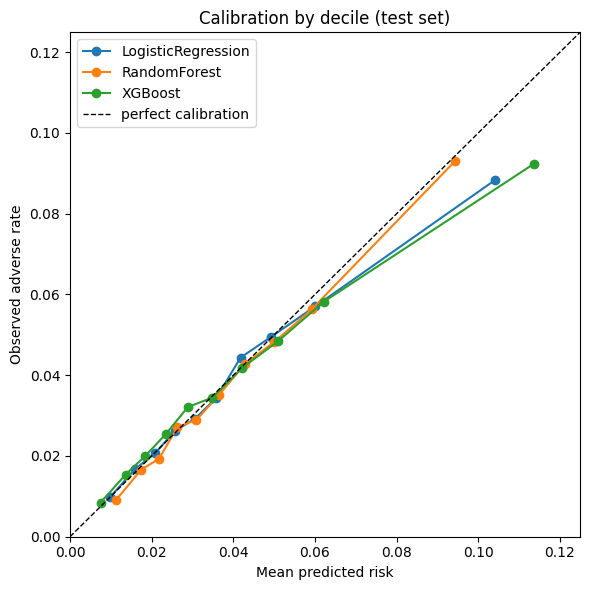

Logistic regression (baseline), by decile:


,mean_predicted,observed_rate,n
decile,,,
0,0.010,0.010,20203
1,0.016,0.017,20203
2,0.021,0.021,20203
3,0.026,0.026,20202
4,0.031,0.029,20203
5,0.036,0.034,20203
6,0.042,0.044,20202
7,0.049,0.049,20203
8,0.060,0.057,20203


In [10]:
fig, ax = plt.subplots(figsize=(6, 6))
calib_tables = {}
for name, p in test_probs.items():
    bins = pd.qcut(p, 10, labels=False, duplicates="drop")
    t = pd.DataFrame({"pred": p, "obs": y_test.values, "decile": bins}).groupby("decile").agg(
        mean_predicted=("pred", "mean"), observed_rate=("obs", "mean"), n=("obs", "size"))
    calib_tables[name] = t
    ax.plot(t["mean_predicted"], t["observed_rate"], marker="o", label=name)
lim = max(max(t["mean_predicted"].max(), t["observed_rate"].max()) for t in calib_tables.values()) * 1.1
ax.plot([0, lim], [0, lim], "k--", lw=1, label="perfect calibration")
ax.set_xlim(0, lim); ax.set_ylim(0, lim)
ax.set_xlabel("Mean predicted risk"); ax.set_ylabel("Observed adverse rate")
ax.set_title("Calibration by decile (test set)"); ax.legend(); plt.tight_layout(); plt.show()
print("Logistic regression (baseline), by decile:")
calib_tables["LogisticRegression"].round(3)

## 8. Does performance hold up over time? (test set by listing year)

In [11]:
yr = d.loc[is_test, LIST_DATE_COL].dt.year.values
by_year = []
for y_ in sorted(np.unique(yr)):
    m = yr == y_
    if y_test[m].nunique() == 2:
        row = {"year": y_, "n": int(m.sum()), "adverse_rate": y_test[m].mean()}
        for name, p in test_probs.items():
            row[f"{name}_PR_AUC"] = average_precision_score(y_test[m], p[m])
            row[f"{name}_ROC_AUC"] = roc_auc_score(y_test[m], p[m])
        by_year.append(row)
pd.DataFrame(by_year).round(3)

,year,n,adverse_rate,LogisticRegression_PR_AUC,LogisticRegression_ROC_AUC,RandomForest_PR_AUC,RandomForest_ROC_AUC,XGBoost_PR_AUC,XGBoost_ROC_AUC
0,2021,34405,0.042,0.091,0.667,0.094,0.669,0.093,0.672
1,2022,44439,0.038,0.088,0.669,0.088,0.674,0.087,0.673
2,2023,47001,0.036,0.077,0.671,0.078,0.672,0.079,0.678
3,2024,49631,0.038,0.080,0.663,0.084,0.677,0.082,0.677
4,2025,26552,0.034,0.070,0.673,0.073,0.679,0.073,0.685


## 9. What the baseline learned (logistic regression coefficients)
Read category bars **within the same feature only**. The encoder keeps every level of a category, so one bar's sign alone doesn't mean much; compare it with the other levels of that feature.

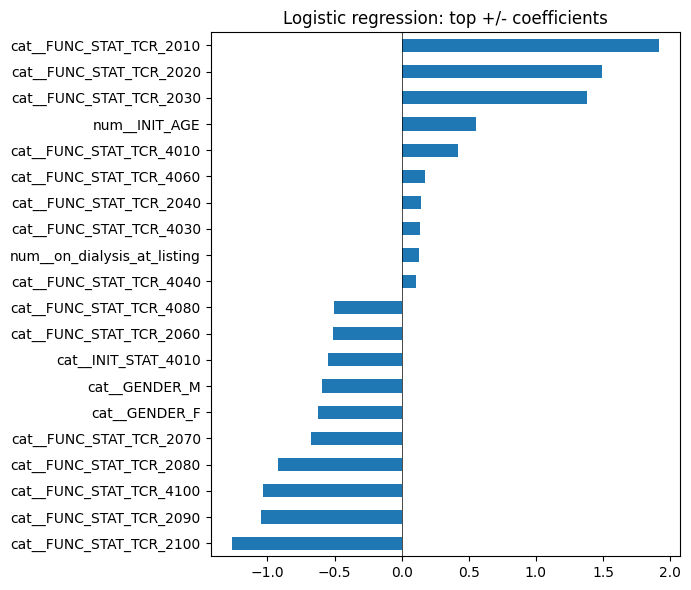

In [12]:
lr = fitted["LogisticRegression"]
names = lr.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(lr.named_steps["model"].coef_[0], index=names).sort_values()
pd.concat([coefs.head(10), coefs.tail(10)]).plot.barh(figsize=(7, 6))
plt.title("Logistic regression: top +/- coefficients"); plt.axvline(0, color="k", lw=0.5)
plt.tight_layout(); plt.show()

## 10. Sensitivity check: drop non-medical removals
Deepti's check: drop administrative removals, transplanted elsewhere, and refused transplant (code 6), refit all three models, and see whether PR-AUC changes. Code 12 stays because it is a medical reason.

Dropping rows that are all `y = 0` raises the prevalence, and PR-AUC rises with prevalence on its own. So compare `PR_AUC_x_random`, not only raw PR-AUC.

In [13]:
if RUN_SENSITIVITY:
    keep = ~d["remcd_group"].isin(NON_MEDICAL_GROUPS).values
    print(f"Dropped {(~keep).sum():,} non-medical removal rows ({(~keep).mean():.1%} of the modeling rows)")
    _, sens_probs = fit_all(X_train[keep[~is_test]], y_train[keep[~is_test]], X_test[keep[is_test]])
    sens = evaluate(y_test[keep[is_test]], sens_probs)
    compare = pd.DataFrame({
        "PR_AUC_main": results["PR_AUC"], "PR_AUC_sensitivity": sens["PR_AUC"],
        "prevalence_main": results["prevalence"], "prevalence_sensitivity": sens["prevalence"],
        "x_random_main": results["PR_AUC_x_random"], "x_random_sensitivity": sens["PR_AUC_x_random"],
        "ROC_AUC_main": results["ROC_AUC"], "ROC_AUC_sensitivity": sens["ROC_AUC"]})
    display(compare.round(3))

Dropped 83,122 non-medical removal rows (18.8% of the modeling rows)
done: LogisticRegression
done: RandomForest
done: XGBoost


,PR_AUC_main,PR_AUC_sensitivity,prevalence_main,prevalence_sensitivity,x_random_main,x_random_sensitivity,ROC_AUC_main,ROC_AUC_sensitivity
model,,,,,,,,
LogisticRegression,0.081,0.091,0.038,0.044,2.151,2.065,0.668,0.666
RandomForest,0.083,0.094,0.038,0.044,2.208,2.119,0.674,0.673
XGBoost,0.083,0.093,0.038,0.044,2.202,2.103,0.676,0.675


## 11. Save test predictions for Task #4 and the fairness check
Saves to Drive, **not** the repo (row-level data, DUA). ETHCAT is saved alongside the predictions for the fairness check only.

In [14]:
# from google.colab import drive; drive.mount('/content/drive')
# preds = d.loc[is_test, ["ETHCAT"]].assign(y_true=y_test.values, **{f"p_{k}": v for k, v in test_probs.items()})
# preds.to_csv("/content/drive/MyDrive/PATH/task2_test_predictions.csv", index=False)

## 12. Summary (printed from the results above)

In [15]:
b, best = results.loc["LogisticRegression"], results["PR_AUC"].idxmax()
gap_pr  = (results["PR_AUC"] - b["PR_AUC"]).abs().max()
gap_roc = (results["ROC_AUC"] - b["ROC_AUC"]).abs().max()
print(f"Cohort: {len(d):,} registrations; 1-year adverse rate {d['y'].mean():.1%} (test {b['prevalence']:.1%}).")
print(f"Baseline (logistic regression): PR-AUC {b['PR_AUC']:.3f} ({b['PR_AUC_x_random']:.1f}x random), "
      f"ROC-AUC {b['ROC_AUC']:.3f}, Brier {b['Brier']:.3f} vs baseline {b['Brier_baseline']:.3f}, BSS {b['BSS']:.3f}.")
print(f"Ensembles vs. baseline: largest gap {gap_pr:.3f} in PR-AUC and {gap_roc:.3f} in ROC-AUC (best PR-AUC: {best}).")
if RUN_SENSITIVITY:
    s = compare.loc["LogisticRegression"]
    print(f"Sensitivity (non-medical removals dropped), baseline: PR-AUC {s['PR_AUC_main']:.3f} -> {s['PR_AUC_sensitivity']:.3f}, "
          f"x random {s['x_random_main']:.2f} -> {s['x_random_sensitivity']:.2f}.")

Cohort: 442,082 registrations; 1-year adverse rate 3.8% (test 3.8%).
Baseline (logistic regression): PR-AUC 0.081 (2.2x random), ROC-AUC 0.668, Brier 0.036 vs baseline 0.036, BSS 0.015.
Ensembles vs. baseline: largest gap 0.002 in PR-AUC and 0.008 in ROC-AUC (best PR-AUC: RandomForest).
Sensitivity (non-medical removals dropped), baseline: PR-AUC 0.081 -> 0.091, x random 2.15 -> 2.06.


## 13. Open questions and next iteration
- **Codes 21 and 23** (died during the transplant procedure) are counted as adverse per the team mapping. The guide suggests discussing whether to treat them as transplants.
- **Cohort:** the guide says to keep WL_ORG KI and KP, but our extract is kidney-alone (KI) only.
- **More listing-time features** in the guide (INIT_EPTS, DGN_TCR, DIAB, TOT_SERUM_ALBUM, NUM_PREV_TX, and others) are not in our extract. Adding them may improve PR-AUC.
- **Geography:** REGION was removed as leaky. The guide suggests LISTING_CTR_CODE instead, with grouping or target encoding fit on training data only.
- **Survival models (Task #3):** codes 6 and 12 should be censored at END_DATE (Deepti).